## Uncovering Hidden Country Segments for Global Development Strategy

### Business Problem

Global development organizations must allocate limited development funds efficiently across countries with diverse socio-economic conditions. A one-size-fits-all strategy often leads to suboptimal outcomes because countries face different challenges related to health, income, trade, inflation, and social development.

The objective of this project is to use unsupervised machine learning techniques to identify naturally occurring groups of countries based on socio-economic indicators. These segments will help policymakers design targeted development strategies and prioritize aid allocation more effectively.

### Project Objectives

- Explore socio-economic characteristics of countries.
- Identify patterns and relationships among development indicators.
- Reduce dimensionality using PCA.
- Discover country segments using clustering techniques.
- Compare K-Means, Hierarchical Clustering, and DBSCAN.
- Generate actionable policy recommendations for each identified segment.

In [1]:
import pandas as pd 
import numpy as np

In [2]:
df = pd.read_csv("Country-data.csv")

In [3]:
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


### Dataset Overview

The dataset contains socio-economic and health indicators for multiple countries.

Before performing clustering, we inspect:

- Dataset dimensions
- Data types
- Missing values
- Summary statistics

This helps ensure data quality and identify any preprocessing requirements.

In [7]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe) 

(167, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB
None
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64
<bound method NDFrame.describe of                  country  child_mort  exports  health  imports  income  \
0            Afghanistan        90.2     10.

### Missing Value Analysis

Clustering algorithms are sensitive to missing values. Therefore, we verify whether any features contain null values before proceeding with preprocessing.

### Feature Distribution Analysis

Understanding the distribution of variables helps identify skewness, extreme values, and potential outliers that may influence clustering performance.

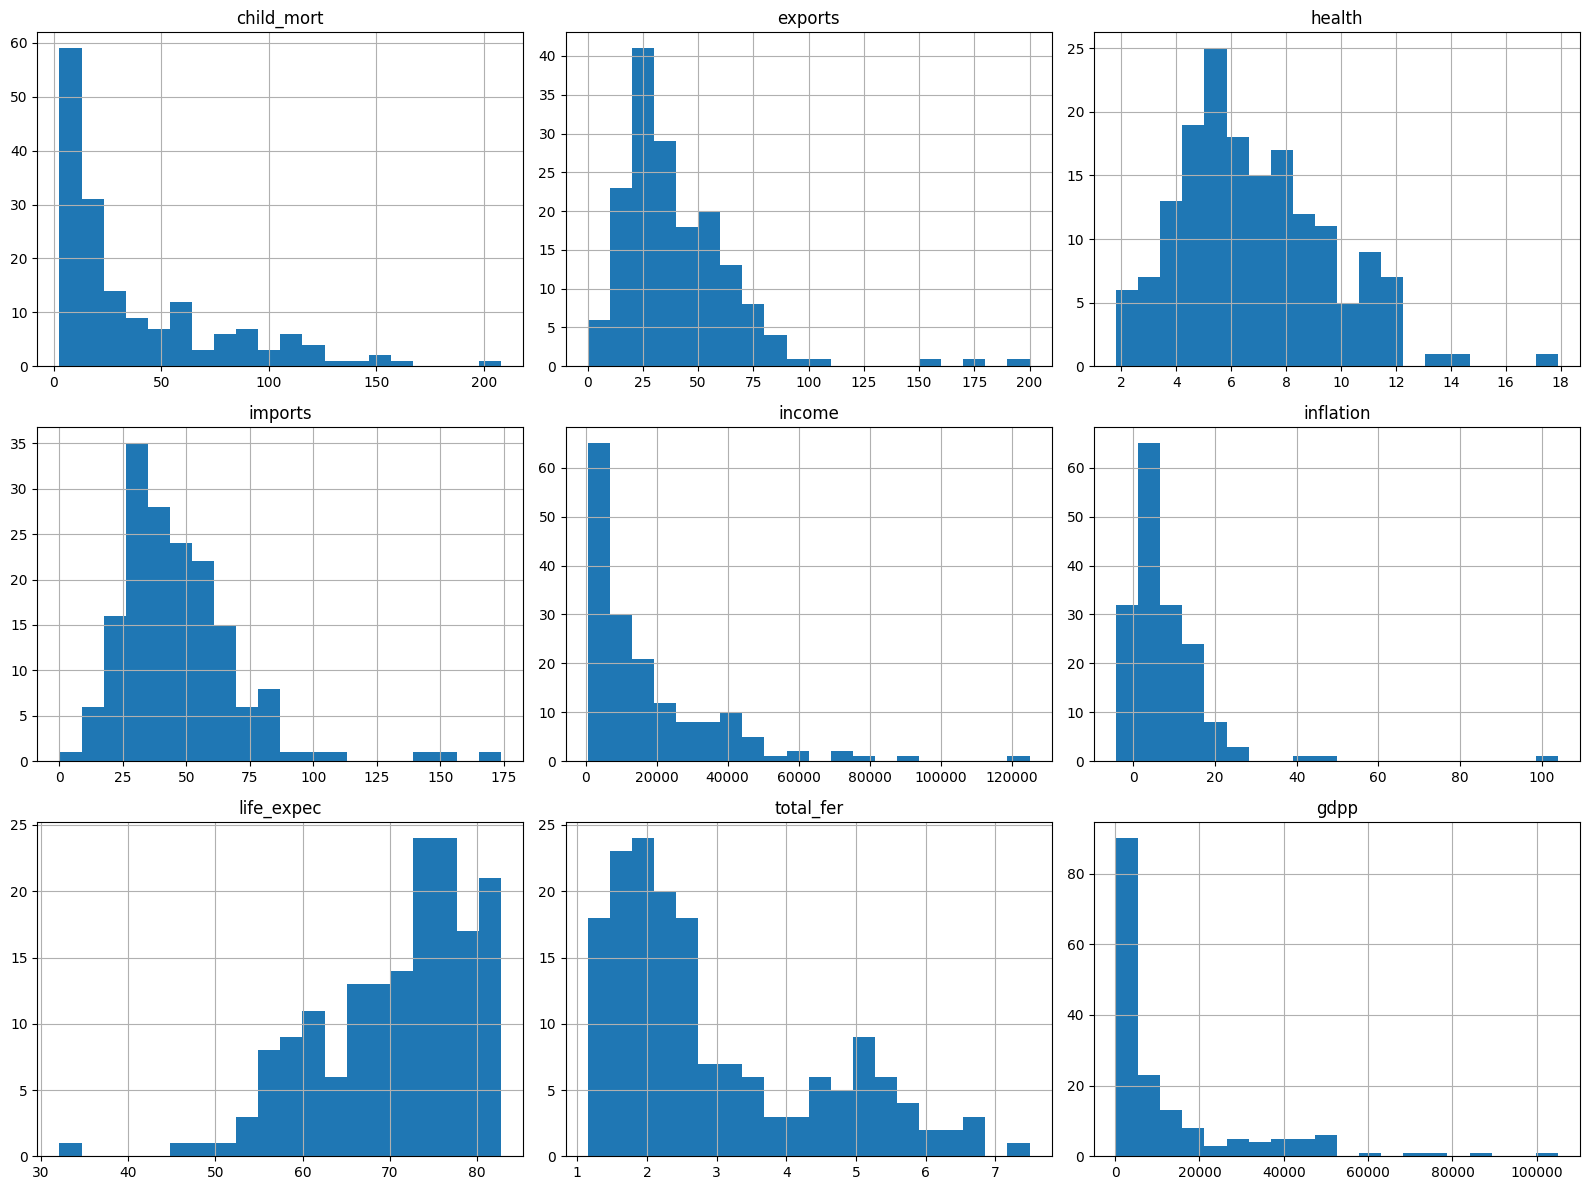

In [9]:
num_cols = df.drop('country', axis=1).columns

df[num_cols].hist(
    figsize=(16,12),
    bins=20
)

plt.tight_layout()
plt.show()

### Outlier Analysis

Socio-economic datasets often contain extreme observations representing highly developed or severely underdeveloped countries.

Outliers are identified using boxplots to understand their presence before deciding whether treatment is necessary.

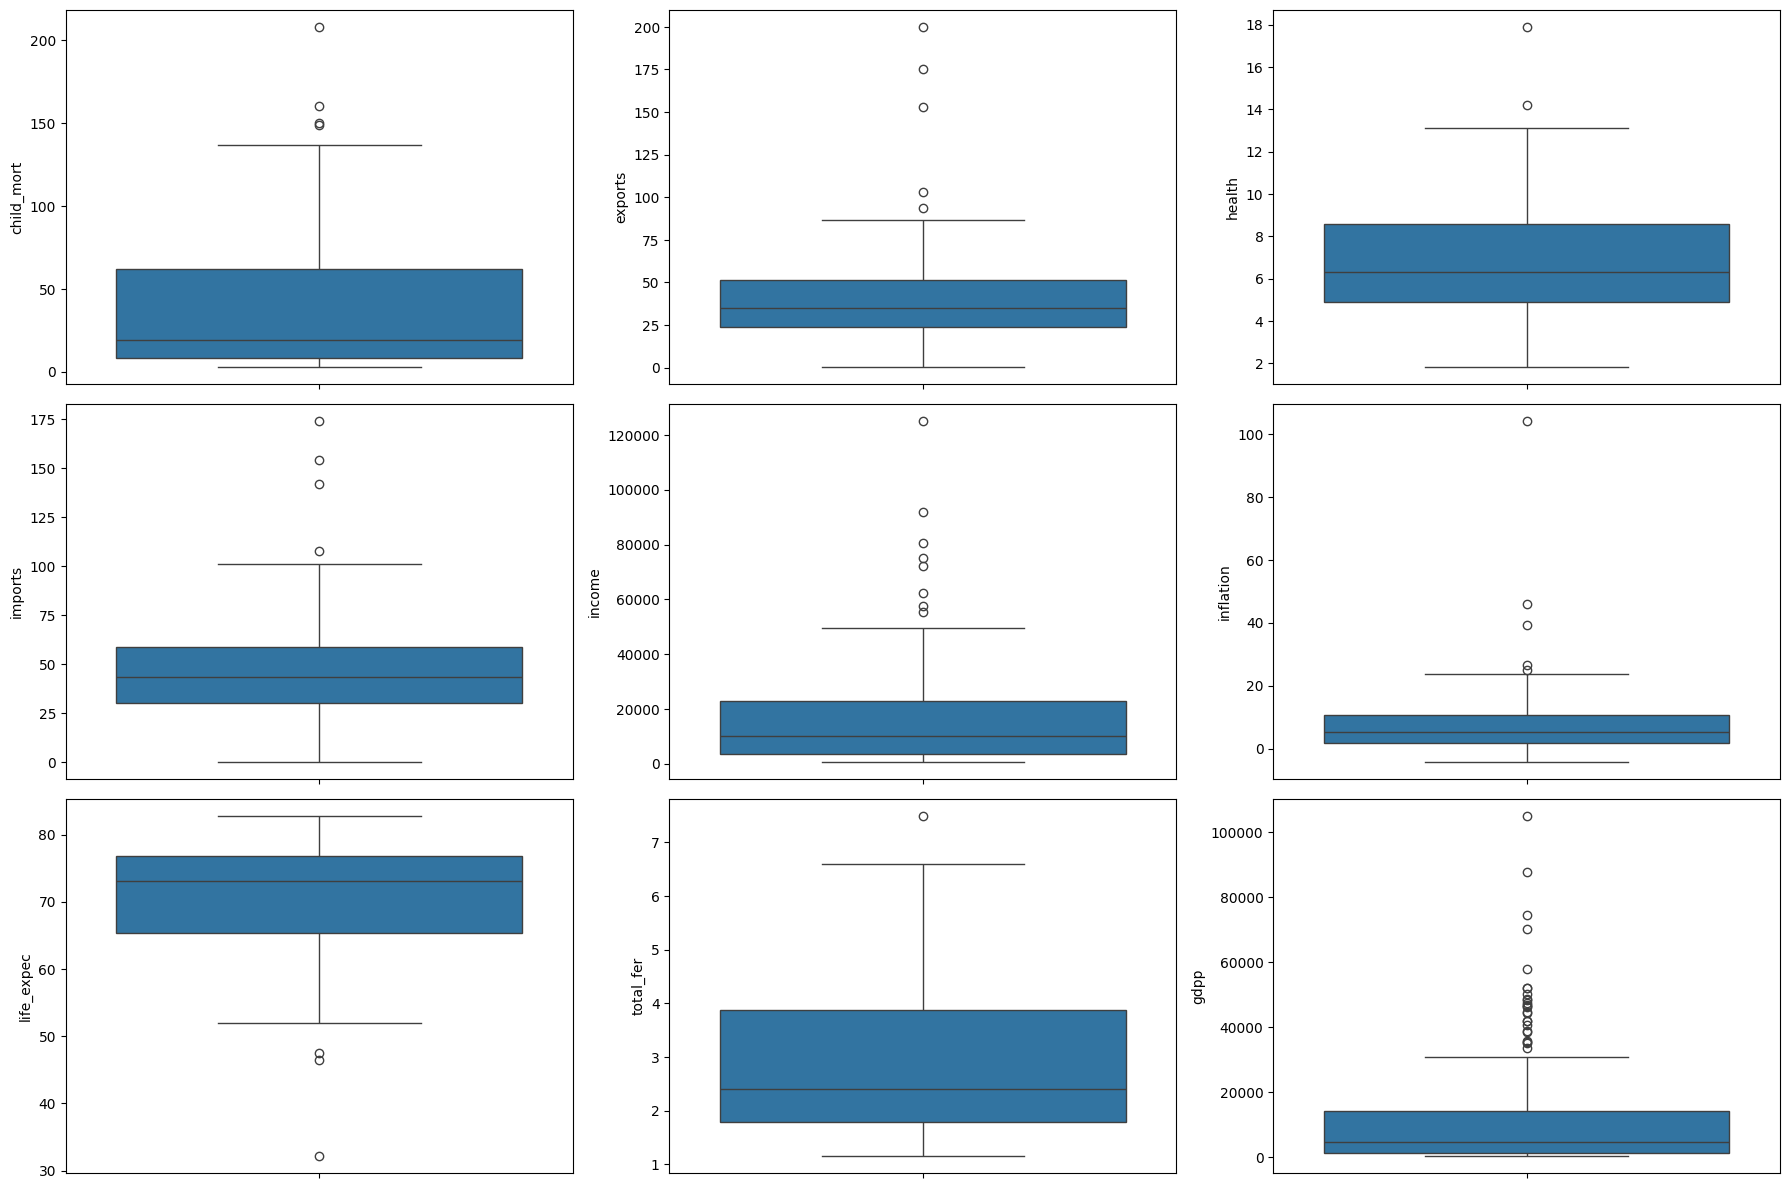

In [10]:
plt.figure(figsize=(18,12))

for i,col in enumerate(num_cols,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[col])

plt.tight_layout()
plt.show()

### Outlier Treatment Decision

Although several variables exhibit extreme values, no outlier capping or removal was performed.

In this problem, extreme observations are often economically meaningful rather than erroneous. Countries with exceptionally high child mortality, low life expectancy, or very low GDP per capita may represent the nations most in need of development assistance.

Removing or capping these observations could reduce the model's ability to identify critical country segments and would diminish the business value of the clustering exercise.

### Skewness Analysis

Highly skewed variables can disproportionately influence distance-based algorithms. Measuring skewness helps understand feature distributions before scaling.

In [11]:
skew_df = pd.DataFrame({
    'Feature': num_cols,
    'Skewness': df[num_cols].skew().values
})

skew_df.sort_values(
    by='Skewness',
    ascending=False
)

,Feature,Skewness
5,inflation,5.154049
1,exports,2.445824
4,income,2.231480
8,gdpp,2.218051
3,imports,1.905276
0,child_mort,1.450774
7,total_fer,0.967092
2,health,0.705746
6,life_expec,-0.970996


### Correlation Analysis

Correlation analysis helps identify relationships among socio-economic indicators and reveals whether some variables carry overlapping information.

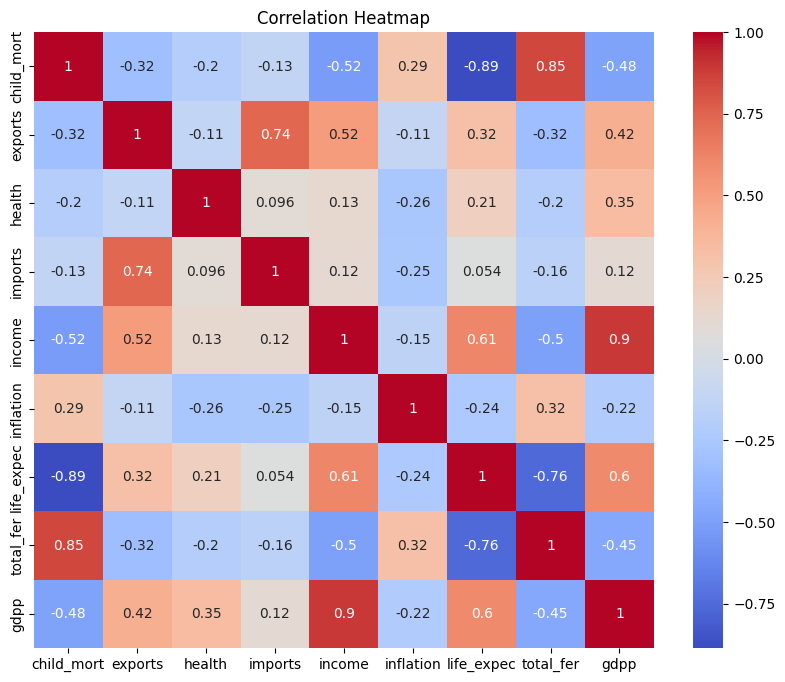

In [12]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

### Best and Worst Performing Countries

Examining countries at the extremes of important indicators provides business context and helps interpret cluster characteristics later.

In [13]:
important_features = [
    'gdpp',
    'income',
    'life_expec',
    'child_mort'
]

for feature in important_features:

    print(f"\nTop 5 Countries - {feature}")

    display(
        df[['country',feature]]
        .sort_values(feature,ascending=False)
        .head()
    )

    print(f"\nBottom 5 Countries - {feature}")

    display(
        df[['country',feature]]
        .sort_values(feature)
        .head()
    )


Top 5 Countries - gdpp


,country,gdpp
91,Luxembourg,105000
114,Norway,87800
145,Switzerland,74600
123,Qatar,70300
44,Denmark,58000



Bottom 5 Countries - gdpp


,country,gdpp
26,Burundi,231
88,Liberia,327
37,"Congo, Dem. Rep.",334
112,Niger,348
132,Sierra Leone,399



Top 5 Countries - income


...

,country,life_expec
66,Haiti,32.1
87,Lesotho,46.5
31,Central African Republic,47.5
166,Zambia,52.0
94,Malawi,53.1



Top 5 Countries - child_mort


,country,child_mort
66,Haiti,208.0
132,Sierra Leone,160.0
32,Chad,150.0
31,Central African Republic,149.0
97,Mali,137.0



Bottom 5 Countries - child_mort


,country,child_mort
68,Iceland,2.6
91,Luxembourg,2.8
133,Singapore,2.8
53,Finland,3.0
144,Sweden,3.0


### Feature Scaling

The variables in the dataset have very different scales. For example, GDP per capita is measured in thousands, whereas life expectancy is measured in years.

Since clustering algorithms rely on distance calculations, all numerical variables are standardized using StandardScaler to ensure equal contribution.

In [14]:
from sklearn.preprocessing import StandardScaler

X = df.drop('country',axis=1)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

X_scaled.head()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.291532,-1.138280,0.279088,-0.082455,-0.808245,0.157336,-1.619092,1.902882,-0.679180
1,-0.538949,-0.479658,-0.097016,0.070837,-0.375369,-0.312347,0.647866,-0.859973,-0.485623
2,-0.272833,-0.099122,-0.966073,-0.641762,-0.220844,0.789274,0.670423,-0.038404,-0.465376
3,2.007808,0.775381,-1.448071,-0.165315,-0.585043,1.387054,-1.179234,2.128151,-0.516268
4,-0.695634,0.160668,-0.286894,0.497568,0.101732,-0.601749,0.704258,-0.541946,-0.041817


## Principal Component Analysis (PCA)

### Why PCA?

The dataset contains multiple correlated socio-economic indicators. PCA is applied to:

- Reduce dimensionality
- Remove redundancy among correlated features
- Improve clustering performance
- Enable easier visualization of country segments

The number of components is selected based on cumulative explained variance.

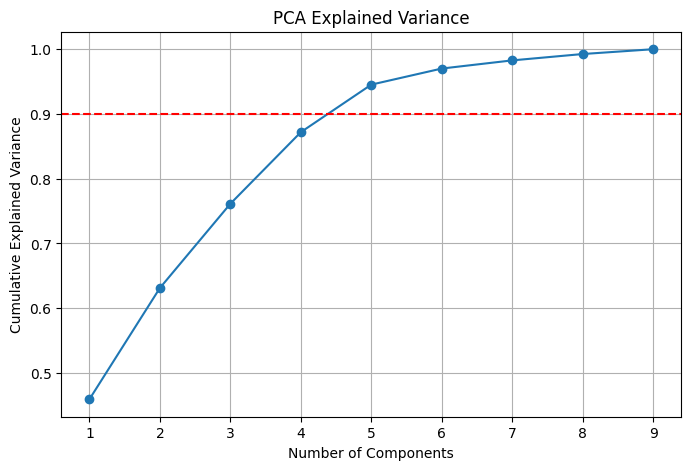

In [15]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA()

pca.fit(X_scaled)

explained_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8,5))

plt.plot(
    range(1,len(explained_variance)+1),
    explained_variance,
    marker='o'
)

plt.axhline(
    y=0.90,
    color='red',
    linestyle='--'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid()

plt.show()

In [16]:
explained_variance

array([0.4595174 , 0.63133365, 0.76137624, 0.87190786, 0.94530998,
       0.97015232, 0.98275663, 0.99256944, 1.        ])

In [22]:
pca = PCA(n_components=5)

X_pca = pca.fit_transform(X_scaled)

print(
    pca.explained_variance_ratio_
)

print(
    pca.explained_variance_ratio_.sum()
)

[0.4595174  0.17181626 0.13004259 0.11053162 0.07340211]
0.9453099756439511


In [24]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1','PC2','PC3','PC4','PC5'],
    index=X.columns
)

loadings

,PC1,PC2,PC3,PC4,PC5
child_mort,-0.419519,0.192884,-0.029544,0.370653,-0.168970
exports,0.283897,0.613163,0.144761,0.003091,0.057616
health,0.150838,-0.243087,-0.596632,0.461897,0.518000
imports,0.161482,0.671821,-0.299927,-0.071907,0.255376
income,0.398441,0.022536,0.301548,0.392159,-0.247150
inflation,-0.193173,-0.008404,0.642520,0.150442,0.714869
life_expec,0.425839,-0.222707,0.113919,-0.203797,0.108220
total_fer,-0.403729,0.155233,0.019549,0.378304,-0.135262
gdpp,0.392645,-0.046022,0.122977,0.531995,-0.180167


In [25]:
pca = PCA(n_components=5)

X_pca = pca.fit_transform(X_scaled)

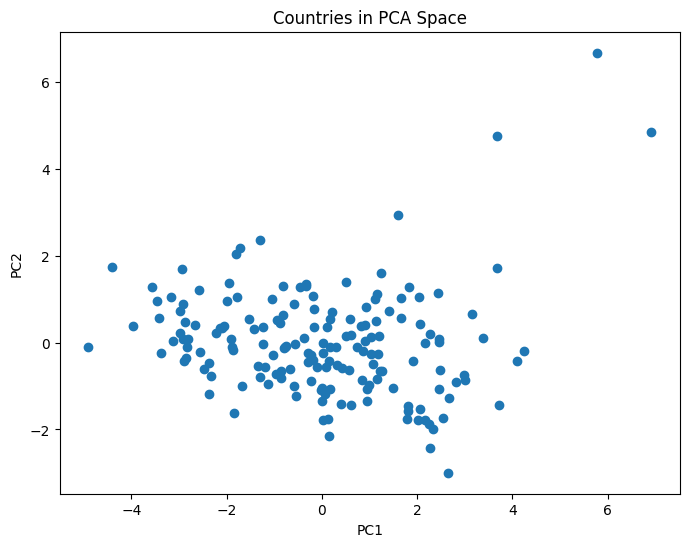

In [26]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1]
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Countries in PCA Space")

plt.show()

### PCA Findings

The first few principal components retain the majority of the information present in the original variables.

These reduced dimensions will be used as inputs to clustering algorithms, allowing country segments to be identified while minimizing noise and redundancy.

### K-Means Clustering

K-Means clustering is used to group countries with similar socio-economic characteristics.

The optimal number of clusters is determined using:

- Elbow Method
- Silhouette Score

These methods help balance cluster compactness and separation.

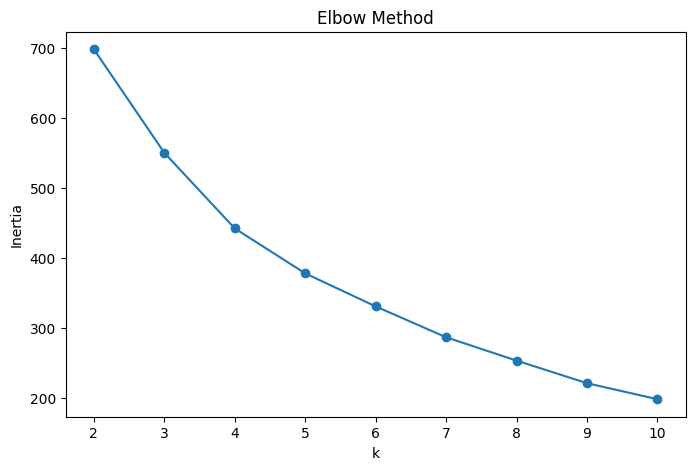

In [20]:
from sklearn.cluster import KMeans

inertia = []

K = range(2,11)

for k in K:

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    km.fit(X_pca)

    inertia.append(
        km.inertia_
    )

plt.figure(figsize=(8,5))

plt.plot(
    K,
    inertia,
    marker='o'
)

plt.xlabel("k")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

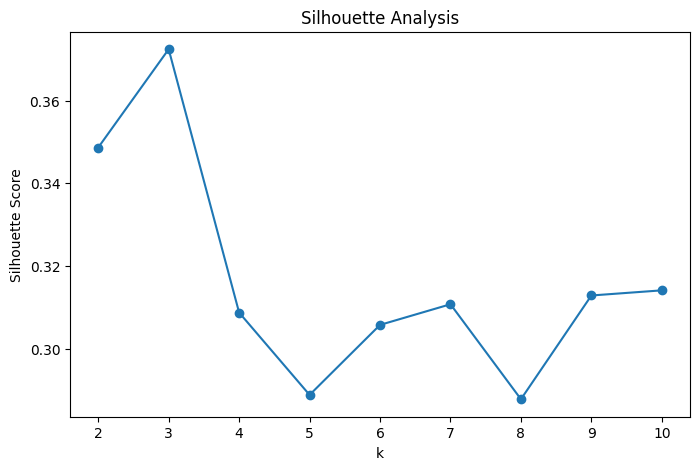

In [21]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(X_pca)

    score = silhouette_score(
        X_pca,
        labels
    )

    scores.append(score)

plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    scores,
    marker='o'
)

plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")

plt.show()

### Selecting the Optimal Number of Clusters

The Elbow Method shows a noticeable reduction in inertia up to approximately three clusters, after which the rate of improvement begins to diminish.

The Silhouette Score reaches its maximum value at k = 3, indicating the best balance between cluster cohesion and cluster separation.

Therefore, three clusters were selected as the optimal segmentation of countries.

In [27]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_pca)

df['KMeans_Cluster'] = clusters

df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,KMeans_Cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,2
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,1
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,1
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,2
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,1


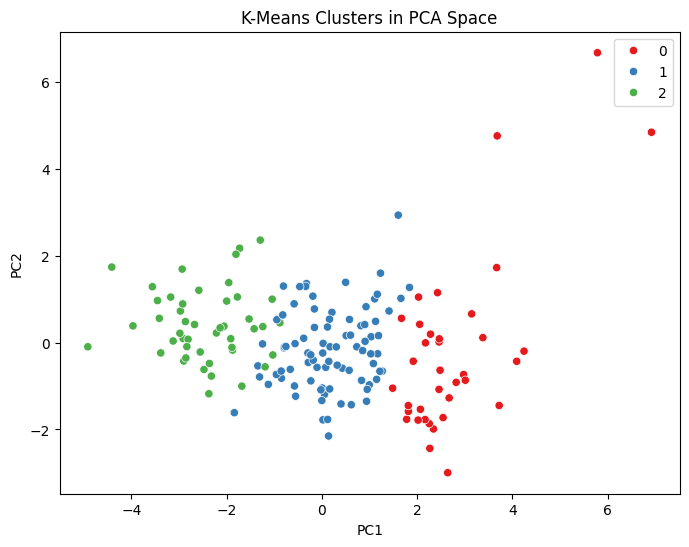

In [28]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=clusters,
    palette='Set1'
)

plt.title("K-Means Clusters in PCA Space")

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.show()

In [29]:
df['KMeans_Cluster'].value_counts()

KMeans_Cluster
1    84
2    47
0    36
Name: count, dtype: int64

In [31]:
cluster_profile = df.groupby(
    'KMeans_Cluster'
).mean(numeric_only=True)

cluster_profile

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
KMeans_Cluster,,,,,,,,,
0,5.000000,58.738889,8.807778,51.491667,45672.222222,2.671250,80.127778,1.752778,42494.444444
1,21.927381,40.243917,6.200952,47.473404,12305.595238,7.600905,72.814286,2.307500,6486.452381
2,92.961702,29.151277,6.388511,42.323404,3942.404255,12.019681,59.187234,5.008085,1922.382979


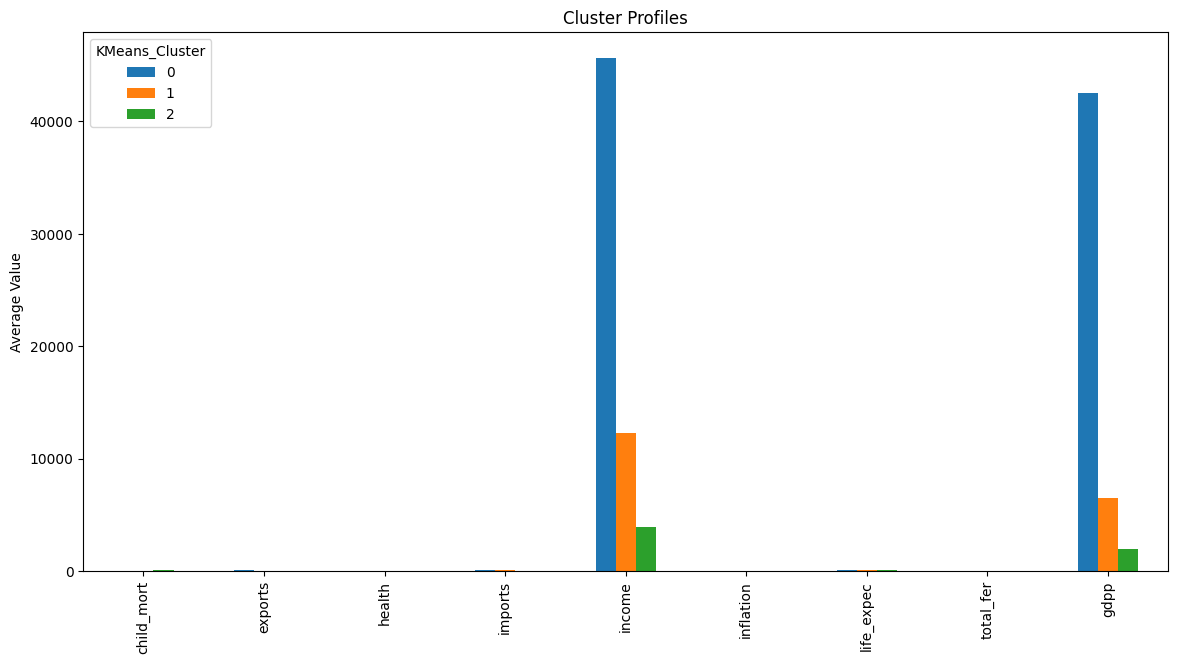

In [32]:
cluster_profile.T.plot(
    kind='bar',
    figsize=(14,7)
)

plt.title(
    "Cluster Profiles"
)

plt.ylabel(
    "Average Value"
)

plt.show()

In [34]:
from scipy.spatial.distance import cdist

distances = cdist(
    X_pca,
    kmeans.cluster_centers_
)

representative_countries = []

for i in range(3):

    idx = np.argmin(
        distances[:,i]
    )

    representative_countries.append(
        df.iloc[idx]['country']
    )

representative_countries

['Iceland', 'Suriname', 'Zambia']

### Hierarchical Clustering

Hierarchical Clustering provides an alternative view of country relationships by building a hierarchy of clusters.

Unlike K-Means, it reveals how clusters merge over different distance thresholds, helping analysts understand nested relationships among country groups.

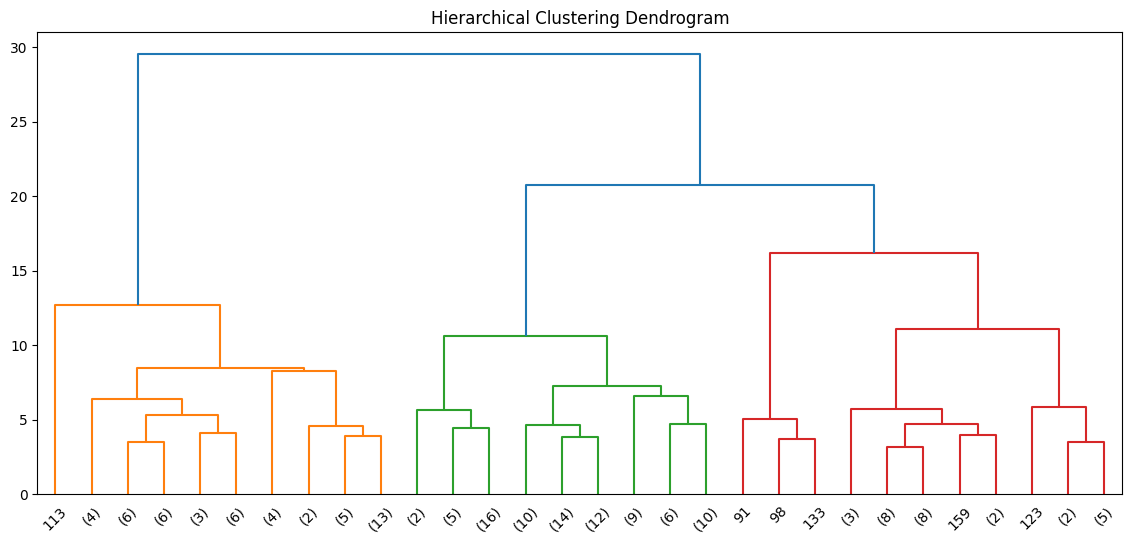

In [35]:
from scipy.cluster.hierarchy import linkage
from scipy.cluster.hierarchy import dendrogram

linked = linkage(
    X_pca,
    method='ward'
)

plt.figure(figsize=(14,6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30
)

plt.title(
    "Hierarchical Clustering Dendrogram"
)

plt.show()

In [36]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=3
)

hc_labels = hc.fit_predict(
    X_pca
)

df['HC_Cluster'] = hc_labels

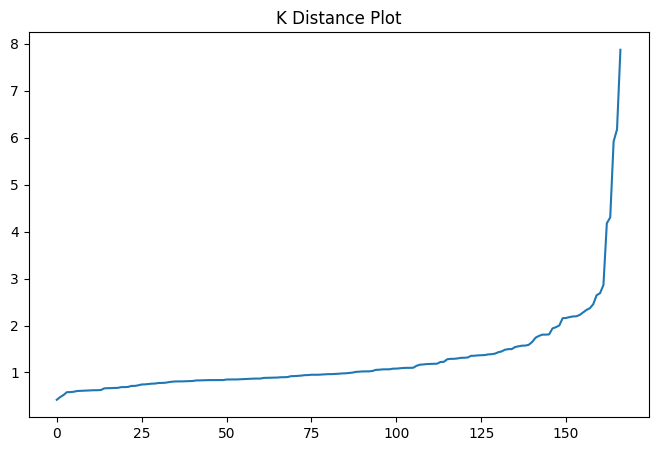

In [37]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(
    n_neighbors=5
)

neighbors_fit = neighbors.fit(
    X_pca
)

distances, indices = neighbors_fit.kneighbors(
    X_pca
)

distances = np.sort(
    distances[:,4]
)

plt.figure(figsize=(8,5))

plt.plot(distances)

plt.title(
    "K Distance Plot"
)

plt.show()

In [38]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=1.2,
    min_samples=5
)

db_labels = dbscan.fit_predict(
    X_pca
)

df['DBSCAN_Cluster'] = db_labels

In [39]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

results = pd.DataFrame({
    'Model':['KMeans','Hierarchical'],
    'Silhouette':[
        silhouette_score(X_pca,clusters),
        silhouette_score(X_pca,hc_labels)
    ],
    'Davies_Bouldin':[
        davies_bouldin_score(X_pca,clusters),
        davies_bouldin_score(X_pca,hc_labels)
    ],
    'Calinski_Harabasz':[
        calinski_harabasz_score(X_pca,clusters),
        calinski_harabasz_score(X_pca,hc_labels)
    ]
})

results

,Model,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,KMeans,0.307977,1.203818,73.419864
1,Hierarchical,0.304272,1.252865,69.531418


### Model Evaluation and Comparison

The clustering algorithms were evaluated using three internal validation metrics:

- Silhouette Score (higher is better)
- Davies-Bouldin Index (lower is better)
- Calinski-Harabasz Index (higher is better)

These metrics assess cluster cohesion, separation, and overall clustering quality.

### Model Comparison Findings

K-Means achieved the highest Silhouette Score and Calinski-Harabasz Score while maintaining the lowest Davies-Bouldin Index.

These results indicate that K-Means produces slightly more compact and better-separated country segments than Hierarchical Clustering.

Therefore, K-Means was selected as the primary segmentation model for business interpretation and policy recommendation.

## Executive Summary

This project analyzed socio-economic indicators from 167 countries to uncover hidden country segments that can support more effective global development planning.

After data preprocessing and feature scaling, Principal Component Analysis (PCA) reduced dimensionality while preserving approximately 94.5% of the total information contained in the dataset.

Three clustering techniques were evaluated:

- K-Means
- Hierarchical Clustering
- DBSCAN

Based on clustering validation metrics, K-Means provided the strongest segmentation performance and identified three distinct country groups.

The discovered segments represent:

1. High-income developed economies with strong health outcomes and high GDP per capita.
2. Developing economies with moderate socio-economic performance.
3. Economically vulnerable countries characterized by high child mortality, lower life expectancy, lower income, and lower GDP per capita.

Representative countries identified for communication and policy discussions were:

- Iceland
- Suriname
- Zambia

The results demonstrate that countries possess significantly different development profiles and therefore require targeted rather than universal policy interventions.

### Country Segment Interpretation

#### Segment 0 – Advanced Economies

Characteristics:

- Highest income levels
- Highest GDP per capita
- Highest life expectancy
- Lowest child mortality
- Lowest fertility rates

Representative Country: Iceland

Policy Focus:

- Sustainable growth
- Innovation and technology investment
- Climate resilience
- Knowledge sharing with developing nations

---

#### Segment 1 – Emerging and Developing Economies

Characteristics:

- Moderate income
- Moderate GDP per capita
- Improving health outcomes
- Balanced trade activity

Representative Country: Suriname

Policy Focus:

- Industrial development
- Workforce skill enhancement
- Infrastructure expansion
- Trade competitiveness

---

#### Segment 2 – High Priority Development Countries

Characteristics:

- Lowest income levels
- Lowest GDP per capita
- Highest child mortality
- Lowest life expectancy
- Highest fertility rates

Representative Country: Zambia

Policy Focus:

- Healthcare access
- Maternal and child welfare
- Poverty reduction
- Education and basic infrastructure investment

## Business Questions and Answers

### Q1. If Standard Scaling was skipped, which features would unfairly dominate clustering?

Without Standard Scaling, large-scale variables such as income and gdpp would dominate distance calculations because their numerical values are significantly larger than variables such as life expectancy or health expenditure. As a result, clusters would primarily reflect income differences rather than overall socio-economic conditions.

---

### Q2. Why might capping extreme values be counterproductive?

Extreme observations often represent countries experiencing severe developmental challenges. Capping variables such as child mortality or very low GDP levels would reduce the visibility of countries most in need of aid and weaken the ability of clustering algorithms to identify critical development segments.

---

### Q3. What does a very high Silhouette Score imply?

A high Silhouette Score indicates that observations within a cluster are highly similar to each other while remaining well separated from observations in other clusters. This suggests strong cluster cohesion and clear separation between country segments.

---

### Q4. What unique insight does a dendrogram provide?

A dendrogram reveals the hierarchical relationships between clusters and shows how country groups merge at different distance thresholds. Unlike K-Means, it provides insight into the relative similarity between clusters and allows analysts to explore multiple segmentation levels.

---

### Q5. What policy goal should be set for Segment A versus Segment B?

For Segment A (high income and high health spending), the policy objective should focus on sustainability, innovation, and long-term economic resilience.

For Segment B (low income and low health spending), the policy objective should prioritize poverty reduction, healthcare access, education, and basic infrastructure development.

---

### Q6. What is the business purpose of identifying representative countries?

Representative countries provide a concrete example of the typical characteristics of a segment. They simplify communication with policymakers, improve stakeholder understanding, and make cluster findings easier to translate into actionable development strategies.

---

### Q7. What policy recommendation should be made for countries with high trade activity but low GDP per capita?

Countries with strong exports and imports but relatively low GDP per capita should focus on increasing domestic value creation. Recommended actions include industrial upgrading, local manufacturing development, workforce skill enhancement, and moving higher in global value chains to capture greater economic benefits from trade.

In [40]:
!jupyter nbconvert --to html Global_Development_Strategy.ipynb

[NbConvertApp] Converting notebook Global_Development_Strategy.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 11 image(s).
[NbConvertApp] Writing 921385 bytes to Global_Development_Strategy.html
